### 1. Importing liberaries

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
import umap
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report, silhouette_score
import warnings
warnings.filterwarnings('ignore')

### 2. Loading data and models

In [40]:
import joblib

model = joblib.load("/content/best_diabetes_model.pkl")
scaler = joblib.load("/content/scaler.pkl")

In [41]:
df = pd.read_csv('/content/cleaned_data.csv')

In [42]:
df_clean = df.drop_duplicates().copy()

selected_cols = [
        'RIDAGEYR', 'RIAGENDR', 'BMXHT',
        'BMXWT', 'BMXBMI',
        'SLD010H', 'physically_active',
        'smoking_status', 'alcohol_use'
    ]

X = df_clean[selected_cols]
Y = df['diabetes']

### 3. Using Clustering

#### 3.1 Scale data for Clustering

In [43]:
minmax_scale = MinMaxScaler()
mm_scale = minmax_scale.fit_transform(df)

df_scaled = pd.DataFrame(data=mm_scale, columns=df.columns)

### 4. Elbow method for Clustering

#### 4.1 DBSCAN

In [44]:
out_percent_list = []

for ms in [3, 5, 10]:
    for eps in [0.05, 0.1, 0.2, 0.5, 1.0]:
        db_model = DBSCAN(eps=eps, min_samples=ms)
        db_labels = db_model.fit_predict(df_scaled)

        percent_of_outlier = 100 * np.sum(db_labels == -1) / len(db_labels)
        out_percent_list.append(percent_of_outlier)

        print(f"For eps {eps}, min sample {ms}")
        print(f"Number Outliers: {np.sum(db_labels == -1)}")
        print(f"Number of clusters: {len(np.unique(db_labels[db_labels != -1]))}\n")

For eps 0.05, min sample 3
Number Outliers: 8714
Number of clusters: 1906

For eps 0.1, min sample 3
Number Outliers: 8714
Number of clusters: 1906

For eps 0.2, min sample 3
Number Outliers: 8709
Number of clusters: 1907

For eps 0.5, min sample 3
Number Outliers: 8304
Number of clusters: 1985

For eps 1.0, min sample 3
Number Outliers: 2401
Number of clusters: 1050

For eps 0.05, min sample 5
Number Outliers: 11717
Number of clusters: 1030

For eps 0.1, min sample 5
Number Outliers: 11717
Number of clusters: 1030

For eps 0.2, min sample 5
Number Outliers: 11712
Number of clusters: 1031

For eps 0.5, min sample 5
Number Outliers: 11509
Number of clusters: 1051

For eps 1.0, min sample 5
Number Outliers: 4100
Number of clusters: 629

For eps 0.05, min sample 10
Number Outliers: 17258
Number of clusters: 176

For eps 0.1, min sample 10
Number Outliers: 17258
Number of clusters: 176

For eps 0.2, min sample 10
Number Outliers: 17258
Number of clusters: 176

For eps 0.5, min sample 10
Nu

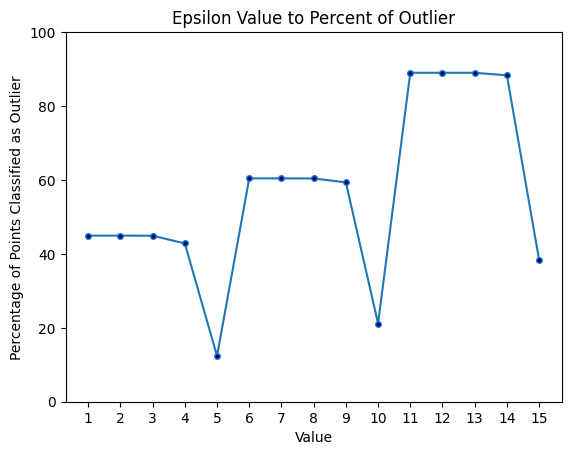

In [45]:
plt.plot(range(1, 16, 1), out_percent_list, marker='o', markerfacecolor='darkblue', markersize=4)
plt.yticks(range(0, 101, 20))
plt.xticks(range(1, 16, 1))
plt.ylabel("Percentage of Points Classified as Outlier")
plt.xlabel("Value")
plt.title("Epsilon Value to Percent of Outlier")
plt.show()

#### 4.2 KMeans

In [46]:
ss = []
inertia = []
for k in range(1, 21):
    model = KMeans(n_clusters=k, random_state=119)
    model = model.fit(df_scaled)

    inertia.append(model.inertia_)
    if k > 1:
        score = silhouette_score(df_scaled, model.labels_)
        ss.append(score)

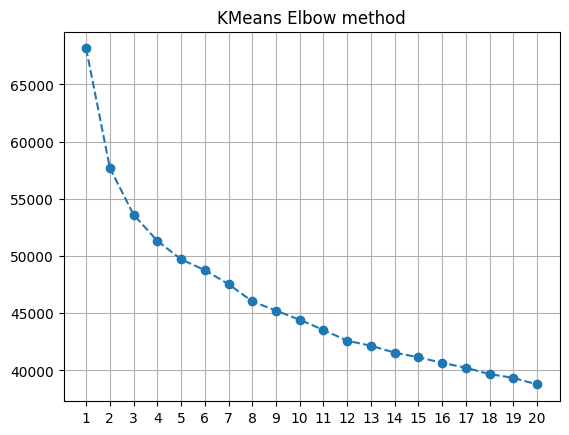

In [47]:
plt.plot(range(1, 21), inertia, 'o--')
plt.title("KMeans Elbow method", fontsize=12)
plt.xticks(range(1,21))
plt.grid()
plt.show()

### 5. Dimensionality Reduction

#### 5.1 PCA

In [48]:
pca_explain_variance = []
for components in range(1, 31):
    pca_model = PCA(n_components=components)
    pca = pca_model.fit(df_scaled)

    pca_explain_variance.append(np.sum(pca.explained_variance_ratio_))

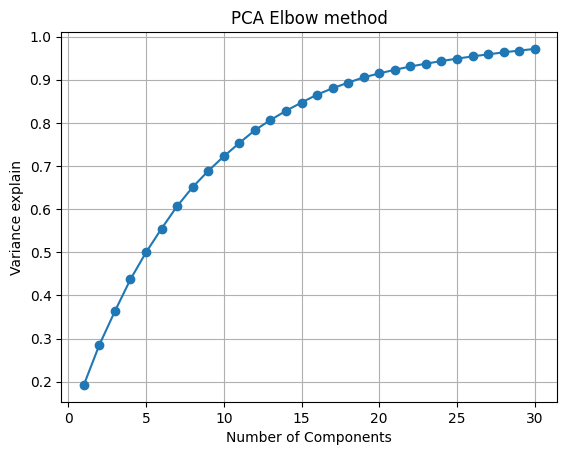

In [49]:
plt.plot(range(1, 31), pca_explain_variance, marker='o')
plt.title("PCA Elbow method", fontsize=12)
plt.xlabel("Number of Components")
plt.ylabel("Variance explain")
plt.grid()
plt.show()

#### 5.2 UMAP

In [ ]:
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    random_state=119
)

umap_2d = reducer.fit_transform(df_scaled)

In [ ]:
plt.figure(figsize=(9, 6), dpi=150)
scatter = plt.scatter(
    umap_2d[:, 0],
    umap_2d[:, 1],
    c=Y,
    cmap='coolwarm',
    alpha=0.6,
    s=15
)
plt.title("UMAP 2D Projection of Patient Features", fontsize=13, fontweight='bold')
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 6. Final cluster

In [52]:
kmeans = KMeans(n_clusters=4, random_state=119, n_init=10)
clusters = kmeans.fit_predict(mm_scale)

In [53]:
df_umap_analysis = pd.DataFrame(umap_2d, columns=['UMAP_1', 'UMAP_2'])
df_umap_analysis['Cluster'] = clusters
df_umap_analysis['Diabetes'] = Y.values

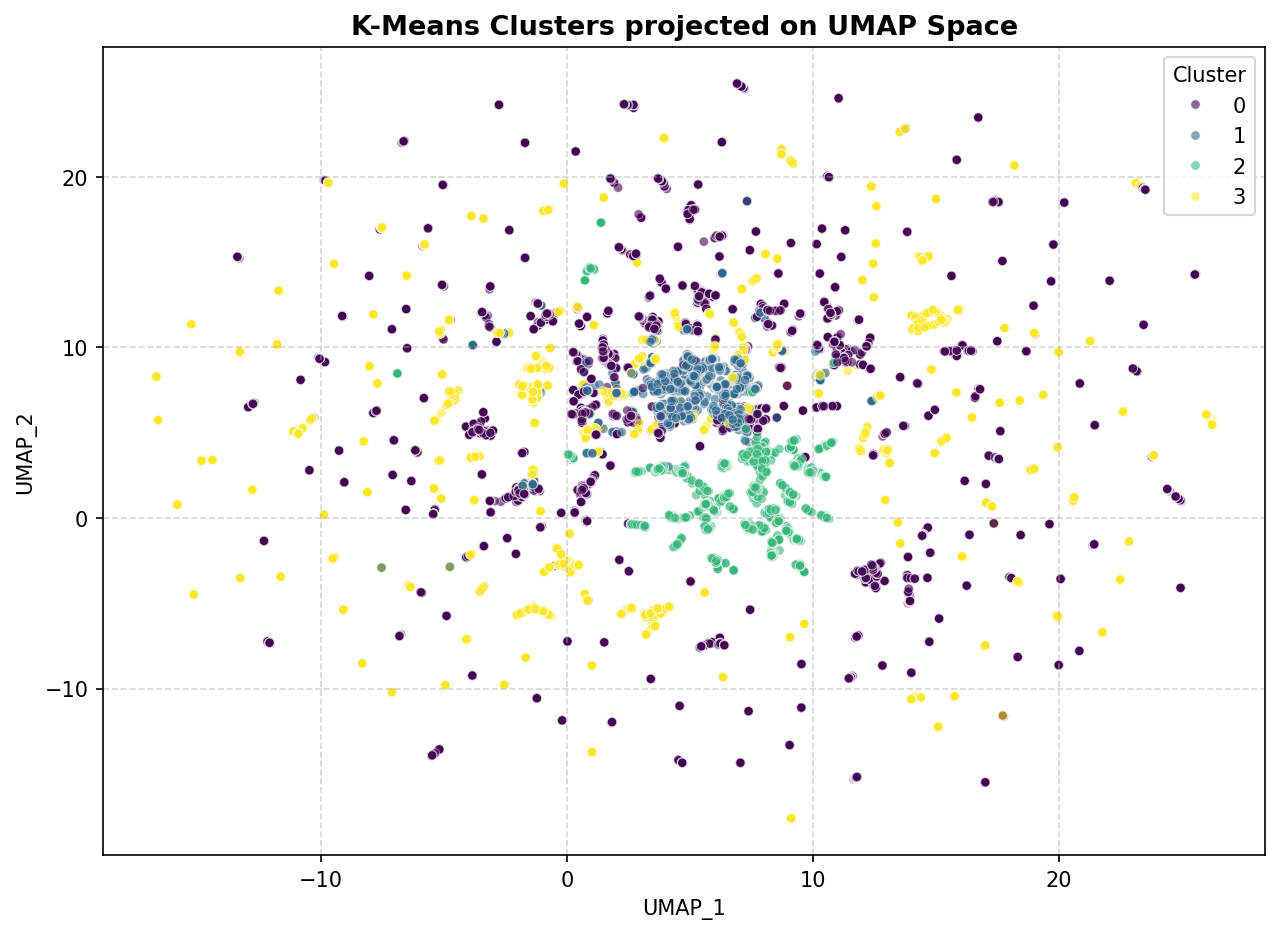

In [54]:
plt.figure(figsize=(10, 7), dpi=150)
sns.scatterplot(
    data=df_umap_analysis,
    x='UMAP_1',
    y='UMAP_2',
    hue='Cluster',
    palette='viridis',
    alpha=0.6,
    s=20
)
plt.title("K-Means Clusters projected on UMAP Space", fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 7. Saving Results

In [55]:
df_results = pd.DataFrame({
    'SEQN': df['SEQN'] if 'SEQN' in df.columns else df_clean.index,
    'Cluster': clusters,
    'Diabetes': Y.values,
    'UMAP_1': umap_2d[:, 0],
    'UMAP_2': umap_2d[:, 1]
})

df_results.to_csv("clustering_results.csv", index=False)

In [56]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")

['kmeans_model.pkl']

In [57]:
cluster_summary = df_results.groupby('Cluster').mean()
cluster_summary.to_csv("cluster_summary.csv")